In [2]:
# CODE 1: Upload the dataset
# This allows us to upload our Excel clickstream dataset into Google Colab.

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving web_clickstream_20000_rows_15_columns.xlsx to web_clickstream_20000_rows_15_columns.xlsx
Dataset uploaded successfully!


In [6]:
# CODE 2: Import libraries
# Pandas is used for data manipulation and analysis.
# NumPy is used for numerical operations.
# Matplotlib and Seaborn are used for visualization.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# CODE 3: Read the Excel dataset
# pd.read_excel() loads the Excel file into a Pandas DataFrame.

df = pd.read_excel("web_clickstream_20000_rows_15_columns.xlsx")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   event_id          event_time  user_id  user_session    page_name  \
0      3220 2026-01-15 02:33:00   100063        506164         Home   
1     11559 2026-02-22 00:27:00   101355        504924  Electronics   
2     19662 2026-03-30 10:38:00   103323        502853         Home   
3     16074 2026-03-14 04:12:00   105666        500720      Fashion   
4     19561 2026-03-29 21:21:00   101448        502865         Cart   

                page_url   event_type  product_id        category   brand  \
0                      /  add_to_cart       11421          Sports      HP   
1  /category/electronics    page_view       12687             NaN    Nike   
2                    NaN  add_to_cart       11458  Home & Kitchen  Adidas   
3      /category/fashion    page_view       11650     Electronics     NaN   
4                  /cart     purchase       12700     Electronics      LG   

     price traffic_source   device  country      campaign  
0  1247.62         Di

In [ ]:
# CODE 4: Check number of rows and columns
# shape returns:
# First value  = number of rows
# Second value = number of columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 20100
Number of columns: 15


In [ ]:
# CODE 5: Display all column names
# This helps us understand what information is available in the dataset.

print("Columns in the dataset:")

for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

Columns in the dataset:
1 : event_id
2 : event_time
3 : user_id
4 : user_session
5 : page_name
6 : page_url
7 : event_type
8 : product_id
9 : category
10 : brand
11 : price
12 : traffic_source
13 : device
14 : country
15 : campaign


In [ ]:
# CODE 6: Display sample records
# head() displays the first 10 rows.
# This helps us understand the structure and values of the dataset.

df.head(10)

,event_id,event_time,user_id,user_session,page_name,page_url,event_type,product_id,category,brand,price,traffic_source,device,country,campaign
0,3220,2026-01-15 02:33:00,100063,506164,Home,/,add_to_cart,11421,Sports,HP,1247.62,Direct,Tablet,Canada,NaN
1,11559,2026-02-22 00:27:00,101355,504924,Electronics,/category/electronics,page_view,12687,NaN,Nike,1173.72,Social,Desktop,India,NaN
2,19662,2026-03-30 10:38:00,103323,502853,Home,NaN,add_to_cart,11458,Home & Kitchen,Adidas,1821.73,Direct,Mobile,Germany,NaN
3,16074,2026-03-14 04:12:00,105666,500720,Fashion,/category/fashion,page_view,11650,Electronics,NaN,1106.90,Direct,Desktop,India,Festive Sale
4,19561,2026-03-29 21:21:00,101448,502865,Cart,/cart,purchase,12700,Electronics,LG,252.07,Direct,Desktop,India,New User
5,19093,2026-03-27 23:20:00,104145,503146,Payment,/payment,page_view,11424,Home & Kitchen,NaN,764.67,Email,Desktop,India,New User
6,9300,2026-02-11 16:06:00,101779,503601,Order Confirmation,/order-confirmation,page_view,12577,Home & Kitchen,Nike,1553.68,Paid Search,Desktop,India,Summer Sale
7,2143,2026-01-10 07:48:00,100374,506458,Products,/products,add_to_cart,12438,Electronics,LG,1807.66,Organic Search,Desktop,India,NaN
8,7082,2026-02-01 12:19:00,101245,500725,Cart,/cart,page_view,11577,Home & Kitchen,NaN,1431.11,Organic Search,Desktop,India,NaN
9,146,2026-01-01 14:25:00,102789,500460,Checkout,/checkout,page_view,12017,Electronics,Samsung,711.96,Paid Search,Mobile,India,NaN


In [ ]:
# CODE 7: Check data types
# This identifies whether each column contains integers,
# floating-point values, dates, or text.

print(df.dtypes)

event_id                   int64
event_time        datetime64[ns]
user_id                    int64
user_session               int64
page_name                 object
page_url                  object
event_type                object
product_id                 int64
category                  object
brand                     object
price                    float64
traffic_source            object
device                    object
country                   object
campaign                  object
dtype: object


In [ ]:
# CODE 8: Detect missing values
# isnull().sum() counts the number of missing values
# present in each column.

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
event_id              0
event_time            0
user_id               0
user_session          0
page_name             0
page_url            301
event_type            0
product_id            0
category           4480
brand              4142
price               503
traffic_source      402
device                0
country               0
campaign          12193
dtype: int64


In [ ]:
# CODE 9: Calculate percentage of missing values
# This tells us how significant the missing values are
# compared with the total number of records.

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage.round(2)
})

print(missing_table)

                Missing Values  Missing Percentage
event_id                     0                0.00
event_time                   0                0.00
user_id                      0                0.00
user_session                 0                0.00
page_name                    0                0.00
page_url                   301                1.50
event_type                   0                0.00
product_id                   0                0.00
category                  4480               22.29
brand                     4142               20.61
price                      503                2.50
traffic_source             402                2.00
device                       0                0.00
country                      0                0.00
campaign                 12193               60.66


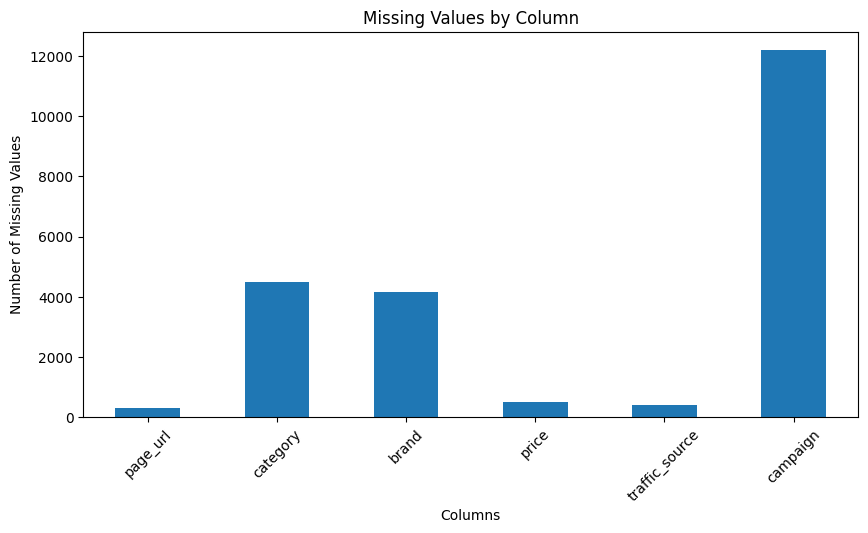

In [ ]:
# CODE 10: Visualize missing values
# A bar chart makes it easier to identify which columns
# contain the highest number of missing values.

missing = df.isnull().sum()

missing = missing[missing > 0]

plt.figure(figsize=(10, 5))
missing.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# CODE 11: Remove duplicate records
# duplicated() identifies duplicate rows.
# drop_duplicates() removes them.

before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicate rows removed:", before - after)

Rows before removing duplicates: 20100
Rows after removing duplicates: 20000
Duplicate rows removed: 100


In [ ]:
# CODE 12: Handle missing values
# Text columns are filled with "Unknown".
# Numerical price values are filled using the median price.
# This prevents missing values from causing problems later.

text_columns = [
    "brand",
    "category",
    "campaign",
    "page_url",
    "traffic_source"
]

for column in text_columns:
    df[column] = df[column].fillna("Unknown")

# Replace missing prices with the median price
df["price"] = df["price"].fillna(df["price"].median())

print("Missing values handled successfully!")

print(df.isnull().sum())

Missing values handled successfully!
event_id          0
event_time        0
user_id           0
user_session      0
page_name         0
page_url          0
event_type        0
product_id        0
category          0
brand             0
price             0
traffic_source    0
device            0
country           0
campaign          0
dtype: int64


In [ ]:
# CODE 13: Convert event_time into datetime format
# Web analytics requires time-based analysis.
# Converting the column allows us to extract date, hour, day, etc.

df["event_time"] = pd.to_datetime(df["event_time"])

print(df["event_time"].dtype)
print(df["event_time"].head())

datetime64[ns]
0   2026-01-15 02:33:00
1   2026-02-22 00:27:00
2   2026-03-30 10:38:00
3   2026-03-14 04:12:00
4   2026-03-29 21:21:00
Name: event_time, dtype: datetime64[ns]


In [ ]:
# CODE 14: Create time-based features
# We extract useful information from event_time.
# These features can later be used for web traffic analysis.

df["date"] = df["event_time"].dt.date
df["hour"] = df["event_time"].dt.hour
df["day"] = df["event_time"].dt.day_name()

print(df[["event_time", "date", "hour", "day"]].head())

           event_time        date  hour       day
0 2026-01-15 02:33:00  2026-01-15     2  Thursday
1 2026-02-22 00:27:00  2026-02-22     0    Sunday
2 2026-03-30 10:38:00  2026-03-30    10    Monday
3 2026-03-14 04:12:00  2026-03-14     4  Saturday
4 2026-03-29 21:21:00  2026-03-29    21    Sunday


In [ ]:
# CODE 15: Final preprocessing verification
# We check the dataset after preprocessing.
# This confirms that missing values and duplicates
# have been handled successfully.

print("FINAL DATASET INFORMATION")
print("-------------------------")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nFinal sample:")
display(df.head())

FINAL DATASET INFORMATION
-------------------------
Rows: 20000
Columns: 18

Missing values:
event_id          0
event_time        0
user_id           0
user_session      0
page_name         0
page_url          0
event_type        0
product_id        0
category          0
brand             0
price             0
traffic_source    0
device            0
country           0
campaign          0
date              0
hour              0
day               0
dtype: int64

Duplicate rows:
0

Final sample:


,event_id,event_time,user_id,user_session,page_name,page_url,event_type,product_id,category,brand,price,traffic_source,device,country,campaign,date,hour,day
0,3220,2026-01-15 02:33:00,100063,506164,Home,/,add_to_cart,11421,Sports,HP,1247.62,Direct,Tablet,Canada,Unknown,2026-01-15,2,Thursday
1,11559,2026-02-22 00:27:00,101355,504924,Electronics,/category/electronics,page_view,12687,Unknown,Nike,1173.72,Social,Desktop,India,Unknown,2026-02-22,0,Sunday
2,19662,2026-03-30 10:38:00,103323,502853,Home,Unknown,add_to_cart,11458,Home & Kitchen,Adidas,1821.73,Direct,Mobile,Germany,Unknown,2026-03-30,10,Monday
3,16074,2026-03-14 04:12:00,105666,500720,Fashion,/category/fashion,page_view,11650,Electronics,Unknown,1106.90,Direct,Desktop,India,Festive Sale,2026-03-14,4,Saturday
4,19561,2026-03-29 21:21:00,101448,502865,Cart,/cart,purchase,12700,Electronics,LG,252.07,Direct,Desktop,India,New User,2026-03-29,21,Sunday


In [8]:
# CODE 16: Sort user activities by time
# We arrange the clickstream data according to:
# 1. User ID
# 2. Session ID
# 3. Event time
#
# This is important because we need to know
# the exact order in which each user visited webpages.

df = df.sort_values(
    by=["user_id", "user_session", "event_time"]
).reset_index(drop=True)

print("User activities sorted successfully!")

print("\nFirst 10 records after sorting:")
display(df[[
    "user_id",
    "user_session",
    "event_time",
    "page_name",
    "event_type"
]].head(10))

User activities sorted successfully!

First 10 records after sorting:


,user_id,user_session,event_time,page_name,event_type
0,100001,500097,2026-02-02 01:35:00,Products,click
1,100001,503663,2026-01-15 02:29:00,Offers,click
2,100001,505367,2026-03-04 13:11:00,Home,remove_from_cart
3,100001,505823,2026-03-16 08:52:00,Electronics,click
4,100002,500153,2026-02-17 01:49:00,Electronics,add_to_cart
5,100002,505184,2026-01-29 01:10:00,Home,purchase
6,100003,503337,2026-03-14 16:07:00,Blog,click
7,100004,501587,2026-03-16 05:22:00,Electronics,click
8,100004,501657,2026-02-12 19:45:00,Products,page_view
9,100004,502454,2026-03-30 13:34:00,Mobiles,page_view


In [9]:
# CODE 17: Display user navigation sequence
# We select one user session and display
# the webpages visited in chronological order.

sample_session = df["user_session"].dropna().iloc[0]

session_data = df[
    df["user_session"] == sample_session
].sort_values("event_time")

print("Sample Session:", sample_session)
print("\nUser Navigation Sequence:")

display(session_data[[
    "user_id",
    "user_session",
    "event_time",
    "page_name",
    "event_type"
]])

Sample Session: 500097

User Navigation Sequence:


,user_id,user_session,event_time,page_name,event_type
0,100001,500097,2026-02-02 01:35:00,Products,click
12164,103598,500097,2026-02-08 12:39:00,Mobiles,page_view
12807,103795,500097,2026-02-16 19:16:00,Checkout,page_view
8783,102606,500097,2026-03-09 22:08:00,Products,page_view
17757,105308,500097,2026-03-13 22:45:00,Offers,page_view
291,100088,500097,2026-03-23 08:34:00,Home,page_view


In [10]:
# CODE 18: Create page-to-page transitions
# We identify the current page and the next page
# visited by the user in the same session.
#
# Example:
# Home → Products
# Products → Laptop
# Laptop → Cart

df["next_page"] = df.groupby(
    ["user_id", "user_session"]
)["page_name"].shift(-1)

print("Page-to-page transitions created successfully!")

print("\nSample transitions:")
display(df[[
    "user_id",
    "user_session",
    "page_name",
    "next_page"
]].head(15))

Page-to-page transitions created successfully!

Sample transitions:


,user_id,user_session,page_name,next_page
0,100001,500097,Products,NaN
1,100001,503663,Offers,NaN
2,100001,505367,Home,NaN
3,100001,505823,Electronics,NaN
4,100002,500153,Electronics,NaN
5,100002,505184,Home,NaN
6,100003,503337,Blog,NaN
7,100004,501587,Electronics,NaN
8,100004,501657,Products,NaN
9,100004,502454,Mobiles,NaN


In [11]:
# CODE 19: Remove invalid page transitions
# The last page of a session does not have a next page.
# Therefore, we remove rows where next_page is missing.

transitions = df[
    df["page_name"].notna() &
    df["next_page"].notna()
].copy()

print("Valid transitions:", len(transitions))

print("\nSample valid transitions:")
display(transitions[[
    "user_id",
    "user_session",
    "page_name",
    "next_page"
]].head(15))

Valid transitions: 105

Sample valid transitions:


,user_id,user_session,page_name,next_page
383,100110,505234,Offers,Offers
406,100115,503320,Electronics,Electronics
835,100244,503615,Search,Search
1032,100306,500498,Home,Home
1053,100314,500883,Home,Home
1096,100328,502745,Home,Home
1407,100421,506864,Cart,Cart
1583,100471,503406,Home,Home
1732,100519,500959,Blog,Blog
1791,100532,503098,Electronics,Electronics


In [12]:
# CODE 20: Count transition frequency
# We count how many times users moved
# from one webpage to another.

transition_counts = (
    transitions
    .groupby(["page_name", "next_page"])
    .size()
    .reset_index(name="weight")
)

print("Transition frequencies calculated successfully!")

print("\nTop page-to-page transitions:")
display(
    transition_counts
    .sort_values("weight", ascending=False)
    .head(20)
)

Transition frequencies calculated successfully!

Top page-to-page transitions:


,page_name,next_page,weight
9,Home,Home,18
6,Electronics,Electronics,13
15,Products,Products,13
7,Fashion,Fashion,9
11,Mobiles,Mobiles,8
12,Offers,Offers,7
18,Search,Search,6
0,Blog,Blog,5
2,Cart,Cart,5
19,Shoes,Shoes,4


In [13]:
# CODE 21: Create the directed website navigation graph
#
# Nodes represent webpages.
# Edges represent movement from one webpage to another.
# Edge weights represent the number of times
# the transition occurred.

import networkx as nx

G = nx.DiGraph()

for _, row in transition_counts.iterrows():
    G.add_edge(
        row["page_name"],
        row["next_page"],
        weight=row["weight"]
    )

print("Website navigation graph created successfully!")

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Website navigation graph created successfully!
Number of nodes: 15
Number of edges: 20


In [14]:
# CODE 22: Display basic graph information
# We examine the structure of our website graph.

print("WEBSITE GRAPH INFORMATION")
print("-------------------------")

print("Number of webpages (nodes):", G.number_of_nodes())
print("Number of navigation links (edges):", G.number_of_edges())

print("\nWebpages in the graph:")
print(list(G.nodes()))

print("\nSample navigation links:")

for source, destination, data in list(G.edges(data=True))[:15]:
    print(
        source,
        "→",
        destination,
        "| Weight:",
        data["weight"]
    )

WEBSITE GRAPH INFORMATION
-------------------------
Number of webpages (nodes): 15
Number of navigation links (edges): 20

Webpages in the graph:
['Blog', 'Mobiles', 'Cart', 'Checkout', 'Home', 'Contact', 'Electronics', 'Fashion', 'Laptops', 'Offers', 'Order Confirmation', 'Payment', 'Products', 'Shoes', 'Search']

Sample navigation links:
Blog → Blog | Weight: 5
Blog → Mobiles | Weight: 1
Mobiles → Mobiles | Weight: 8
Cart → Cart | Weight: 5
Checkout → Checkout | Weight: 3
Checkout → Home | Weight: 1
Home → Cart | Weight: 1
Home → Home | Weight: 18
Contact → Contact | Weight: 1
Electronics → Electronics | Weight: 13
Fashion → Fashion | Weight: 9
Laptops → Laptops | Weight: 3
Offers → Offers | Weight: 7
Order Confirmation → Order Confirmation | Weight: 3
Payment → Payment | Weight: 2


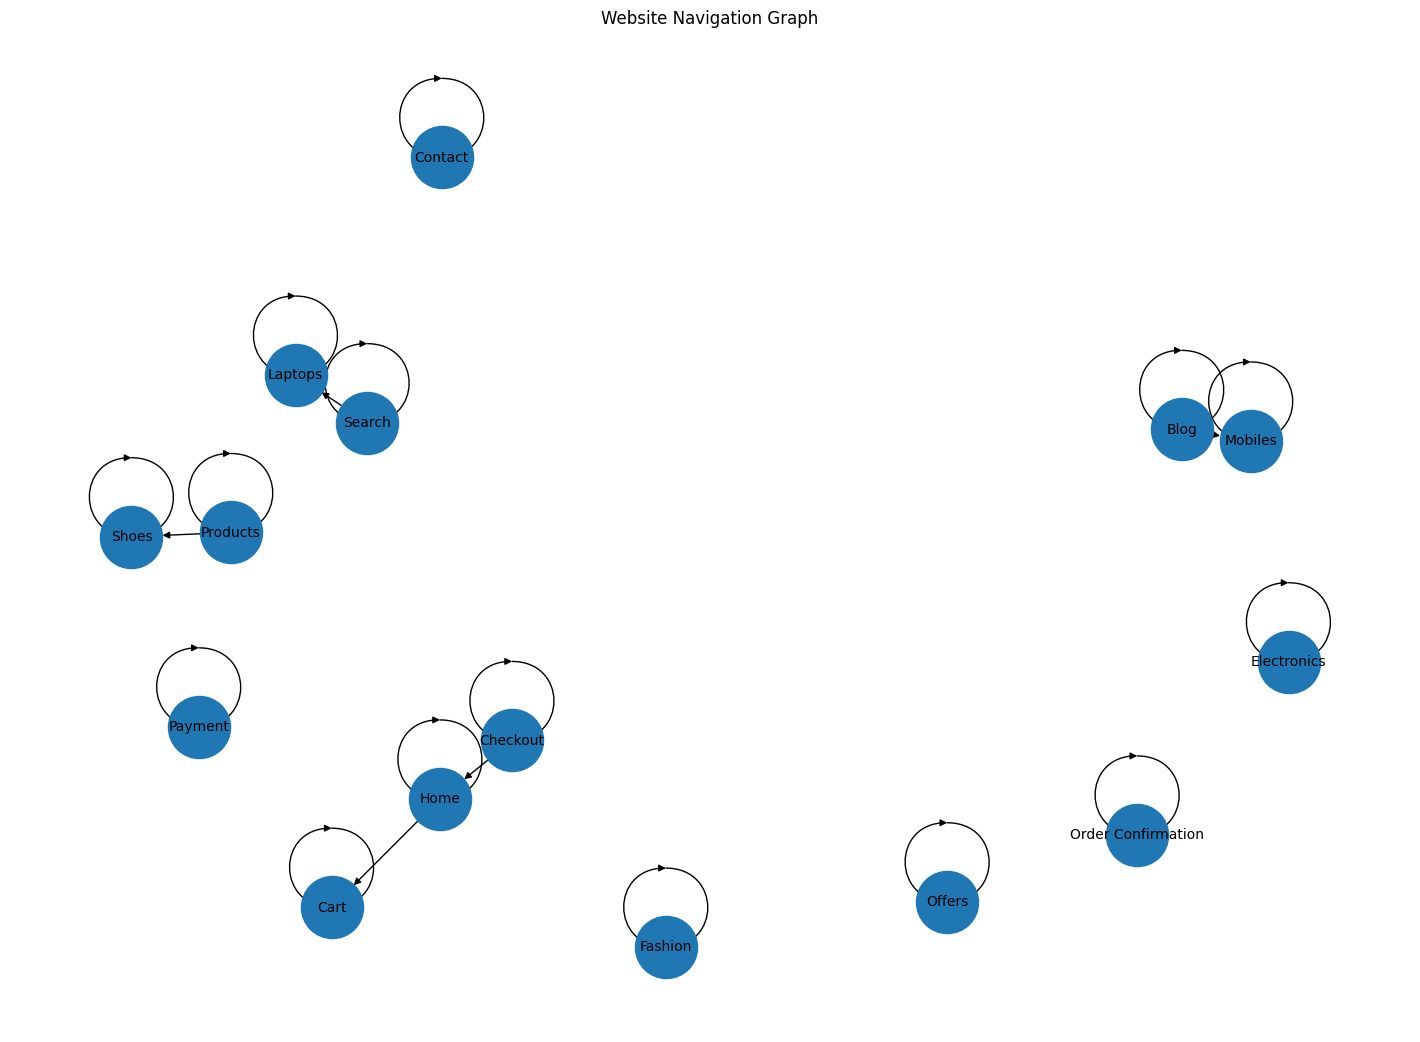

In [15]:
# CODE 23: Visualize the website navigation graph
# We draw the webpages as nodes and navigation
# paths as directed edges.

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2000,
    font_size=10,
    arrows=True
)

plt.title("Website Navigation Graph")
plt.show()

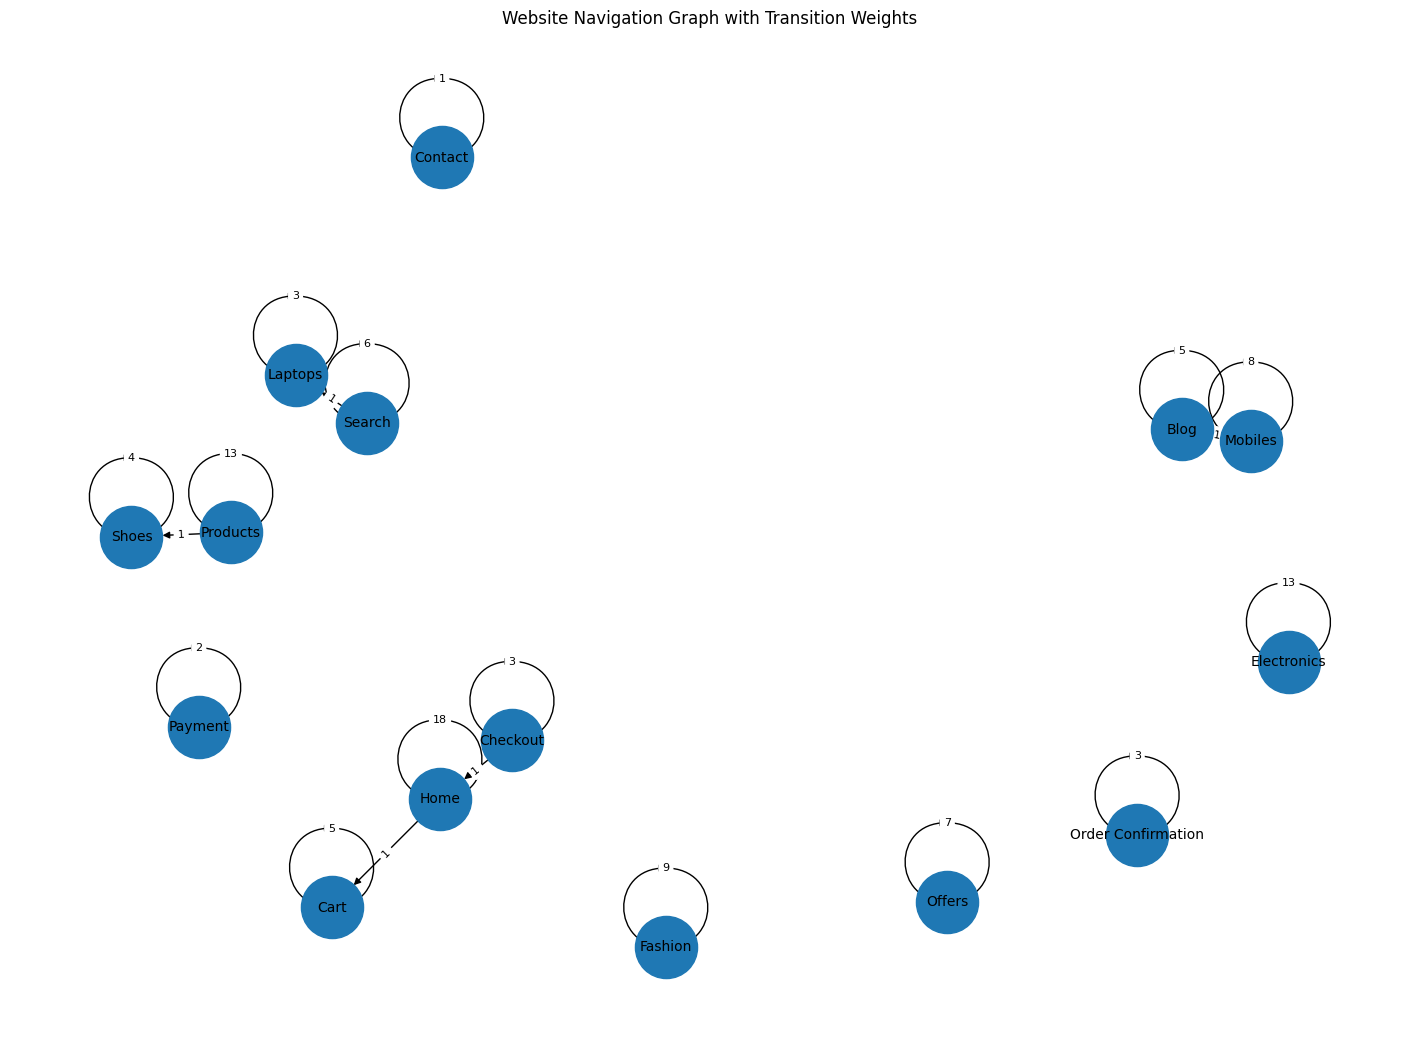

In [16]:
# CODE 24: Visualize navigation frequency
# The edge labels show how many times users
# moved from one webpage to another.

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2000,
    font_size=10,
    arrows=True
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title("Website Navigation Graph with Transition Weights")
plt.show()

In [17]:
# CODE 25: Calculate basic graph statistics
# We calculate the number of nodes, edges,
# density and average degree.

print("BASIC GRAPH STATISTICS")
print("----------------------")

print("Number of Nodes:", G.number_of_nodes())
print("Number of Edges:", G.number_of_edges())

print("Graph Density:", round(nx.density(G), 4))

in_degrees = dict(G.in_degree())
out_degrees = dict(G.out_degree())

print("Average In-Degree:",
      round(sum(in_degrees.values()) / len(in_degrees), 2))

print("Average Out-Degree:",
      round(sum(out_degrees.values()) / len(out_degrees), 2))

BASIC GRAPH STATISTICS
----------------------
Number of Nodes: 15
Number of Edges: 20
Graph Density: 0.0952
Average In-Degree: 1.33
Average Out-Degree: 1.33


In [18]:
# CODE 26: Dijkstra's Shortest Path
# Dijkstra's algorithm finds the shortest/lowest-cost path
# between two webpages in our navigation graph.
#
# In our project:
# Source page = starting webpage
# Destination page = webpage we want to reach
# Weight = navigation frequency
#
# NOTE:
# A high frequency currently means a larger edge weight.
# Therefore, for a true "most frequent/easiest navigation path",
# we will later use a cost value based on frequency.

# Display available webpages
print("Available webpages:")
print(list(G.nodes()))

Available webpages:
['Blog', 'Mobiles', 'Cart', 'Checkout', 'Home', 'Contact', 'Electronics', 'Fashion', 'Laptops', 'Offers', 'Order Confirmation', 'Payment', 'Products', 'Shoes', 'Search']


In [19]:
# CODE 27: Find the shortest path using Dijkstra's algorithm

# Select source and destination webpages
source = list(G.nodes())[0]
destination = list(G.nodes())[-1]

print("Source Page:", source)
print("Destination Page:", destination)

try:
    shortest_path = nx.dijkstra_path(
        G,
        source=source,
        target=destination,
        weight="weight"
    )

    shortest_distance = nx.dijkstra_path_length(
        G,
        source=source,
        target=destination,
        weight="weight"
    )

    print("\nDijkstra Shortest Path:")
    print(" → ".join(shortest_path))

    print("\nPath Cost:", shortest_distance)

except nx.NetworkXNoPath:
    print("\nNo path exists between the selected webpages.")

Source Page: Blog
Destination Page: Search

No path exists between the selected webpages.


In [20]:
# CODE 28: Degree Centrality
# Degree centrality measures how strongly a webpage
# is connected to other webpages.
#
# A higher value indicates more direct connections.

degree_centrality = nx.degree_centrality(G)

degree_df = pd.DataFrame(
    degree_centrality.items(),
    columns=["Page", "Degree Centrality"]
)

degree_df = degree_df.sort_values(
    "Degree Centrality",
    ascending=False
).reset_index(drop=True)

print("DEGREE CENTRALITY")
print("-----------------")

display(degree_df)

DEGREE CENTRALITY
-----------------


,Page,Degree Centrality
0,Home,0.285714
1,Mobiles,0.214286
2,Blog,0.214286
3,Cart,0.214286
4,Checkout,0.214286
5,Search,0.214286
6,Laptops,0.214286
7,Shoes,0.214286
8,Products,0.214286
9,Electronics,0.142857


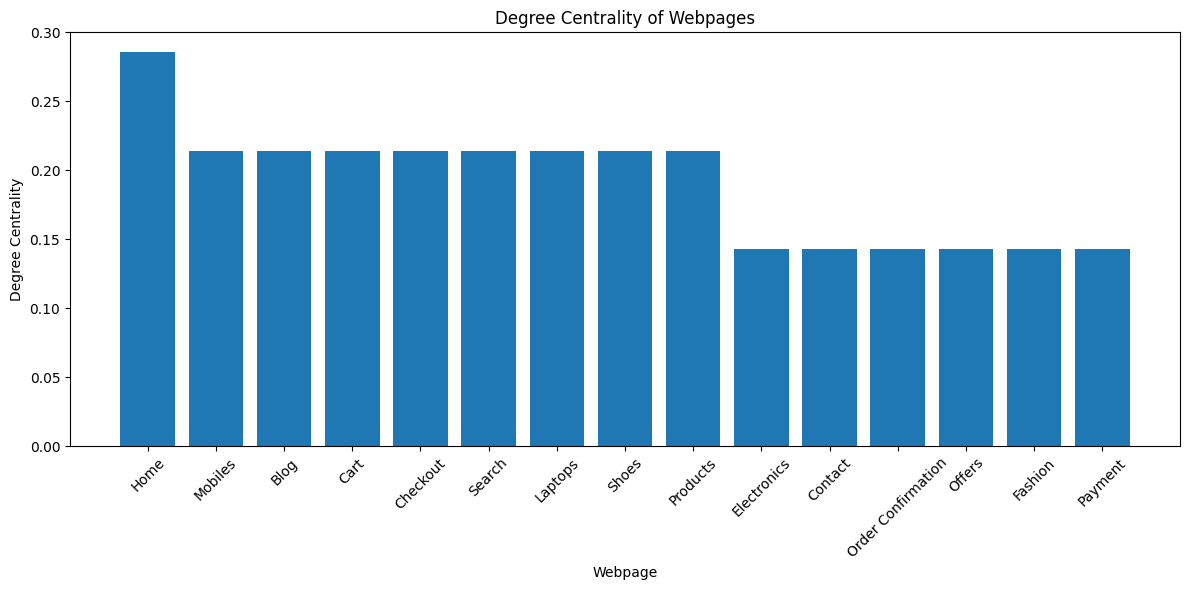

In [21]:
# CODE 29: Visualize Degree Centrality

plt.figure(figsize=(12, 6))

plt.bar(
    degree_df["Page"],
    degree_df["Degree Centrality"]
)

plt.title("Degree Centrality of Webpages")
plt.xlabel("Webpage")
plt.ylabel("Degree Centrality")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
# CODE 30: Closeness Centrality
# Closeness centrality measures how close a webpage
# is to other webpages in the network.

closeness_centrality = nx.closeness_centrality(G)

closeness_df = pd.DataFrame(
    closeness_centrality.items(),
    columns=["Page", "Closeness Centrality"]
)

closeness_df = closeness_df.sort_values(
    "Closeness Centrality",
    ascending=False
).reset_index(drop=True)

print("CLOSENESS CENTRALITY")
print("--------------------")

display(closeness_df)

CLOSENESS CENTRALITY
--------------------


,Page,Closeness Centrality
0,Cart,0.095238
1,Mobiles,0.071429
2,Home,0.071429
3,Shoes,0.071429
4,Laptops,0.071429
5,Blog,0.000000
6,Checkout,0.000000
7,Electronics,0.000000
8,Contact,0.000000
9,Offers,0.000000


In [23]:
# CODE 31: Betweenness Centrality
# Betweenness centrality identifies webpages
# that frequently lie on paths between other webpages.

betweenness_centrality = nx.betweenness_centrality(
    G,
    weight="weight"
)

betweenness_df = pd.DataFrame(
    betweenness_centrality.items(),
    columns=["Page", "Betweenness Centrality"]
)

betweenness_df = betweenness_df.sort_values(
    "Betweenness Centrality",
    ascending=False
).reset_index(drop=True)

print("BETWEENNESS CENTRALITY")
print("----------------------")

display(betweenness_df)

BETWEENNESS CENTRALITY
----------------------


,Page,Betweenness Centrality
0,Home,0.005495
1,Mobiles,0.000000
2,Blog,0.000000
3,Cart,0.000000
4,Checkout,0.000000
5,Contact,0.000000
6,Electronics,0.000000
7,Fashion,0.000000
8,Laptops,0.000000
9,Offers,0.000000


In [24]:
# CODE 32: Eigenvector Centrality
# Eigenvector centrality measures webpage importance
# based not only on the number of connections,
# but also on the importance of connected webpages.

try:
    eigenvector_centrality = nx.eigenvector_centrality(
        G,
        max_iter=1000,
        weight="weight"
    )

    eigenvector_df = pd.DataFrame(
        eigenvector_centrality.items(),
        columns=["Page", "Eigenvector Centrality"]
    )

    eigenvector_df = eigenvector_df.sort_values(
        "Eigenvector Centrality",
        ascending=False
    ).reset_index(drop=True)

    print("EIGENVECTOR CENTRALITY")
    print("----------------------")

    display(eigenvector_df)

except nx.PowerIterationFailedConvergence:
    print("Eigenvector calculation did not converge.")

EIGENVECTOR CENTRALITY
----------------------


,Page,Eigenvector Centrality
0,Home,9.970545e-01
1,Cart,7.669650e-02
2,Electronics,1.570977e-05
3,Products,1.570977e-05
4,Shoes,1.745530e-06
5,Fashion,8.621057e-11
6,Mobiles,2.589581e-12
7,Offers,2.797693e-14
8,Search,2.286072e-16
9,Laptops,7.620241e-17


In [25]:
# CODE 33: PageRank
# PageRank calculates the structural importance
# of webpages based on incoming links and the
# importance of the pages providing those links.

pagerank = nx.pagerank(
    G,
    weight="weight"
)

pagerank_df = pd.DataFrame(
    pagerank.items(),
    columns=["Page", "PageRank"]
)

pagerank_df = pagerank_df.sort_values(
    "PageRank",
    ascending=False
).reset_index(drop=True)

print("PAGERANK RESULTS")
print("----------------")

display(pagerank_df)

PAGERANK RESULTS
----------------


,Page,PageRank
0,Mobiles,0.099047
1,Laptops,0.096491
2,Cart,0.090938
3,Shoes,0.085870
4,Home,0.081476
5,Electronics,0.066667
6,Contact,0.066667
7,Order Confirmation,0.066667
8,Payment,0.066667
9,Offers,0.066667


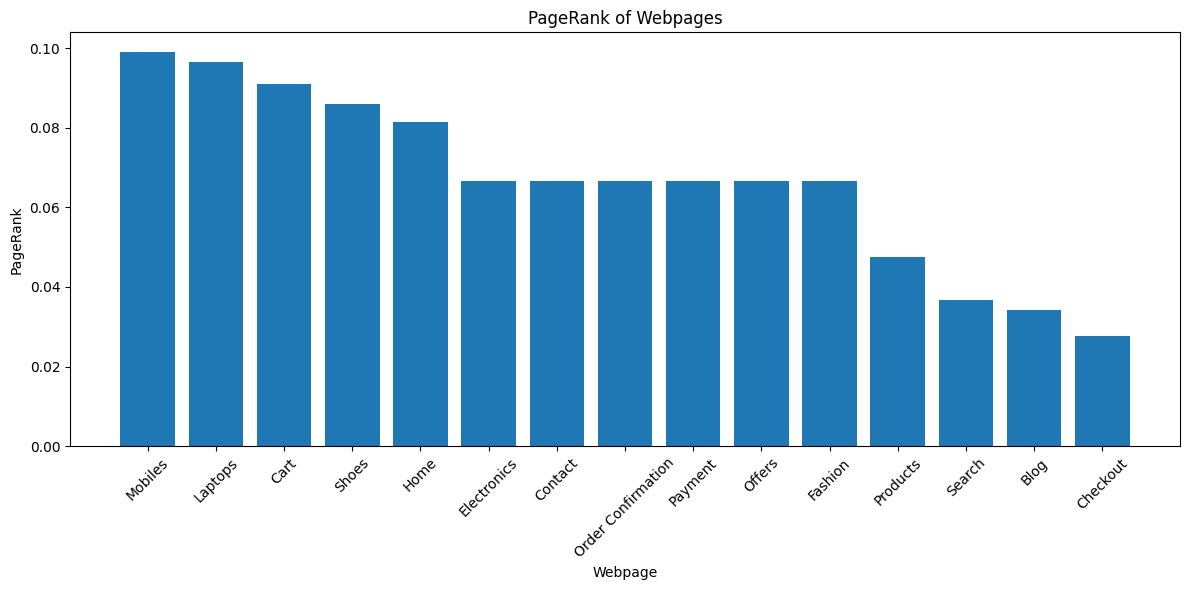

In [26]:
# CODE 34: Visualize PageRank scores

plt.figure(figsize=(12, 6))

plt.bar(
    pagerank_df["Page"],
    pagerank_df["PageRank"]
)

plt.title("PageRank of Webpages")
plt.xlabel("Webpage")
plt.ylabel("PageRank")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# CODE 35: Combine graph centrality results
# This allows us to compare different measures
# for each webpage.

centrality_results = degree_df.merge(
    closeness_df,
    on="Page",
    how="outer"
)

centrality_results = centrality_results.merge(
    betweenness_df,
    on="Page",
    how="outer"
)

centrality_results = centrality_results.merge(
    eigenvector_df,
    on="Page",
    how="outer"
)

centrality_results = centrality_results.merge(
    pagerank_df,
    on="Page",
    how="outer"
)

print("COMBINED CENTRALITY RESULTS")
print("---------------------------")

display(centrality_results)

COMBINED CENTRALITY RESULTS
---------------------------


,Page,Degree Centrality,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality,PageRank
0,Blog,0.214286,0.000000,0.000000,8.892125e-19,0.034286
1,Cart,0.214286,0.095238,0.000000,7.669650e-02,0.090938
2,Checkout,0.214286,0.000000,0.000000,4.071179e-25,0.027586
3,Contact,0.142857,0.000000,0.000000,5.924345e-36,0.066667
4,Electronics,0.142857,0.000000,0.000000,1.570977e-05,0.066667
5,Fashion,0.142857,0.000000,0.000000,8.621057e-11,0.066667
6,Home,0.285714,0.071429,0.005495,9.970545e-01,0.081476
7,Laptops,0.214286,0.071429,0.000000,7.620241e-17,0.096491
8,Mobiles,0.214286,0.071429,0.000000,2.589581e-12,0.099047
9,Offers,0.142857,0.000000,0.000000,2.797693e-14,0.066667


In [28]:
# CODE 36: Community Detection
# Community detection identifies groups of webpages
# that are strongly connected to each other.
#
# For this analysis, we use the Louvain method
# if it is available in the installed NetworkX version.

try:
    communities = nx.community.louvain_communities(
        G,
        weight="weight",
        seed=42
    )

    print("Number of communities:", len(communities))

    for i, community in enumerate(communities, start=1):
        print(f"\nCommunity {i}:")
        print(list(community))

except AttributeError:
    print("Louvain community detection is not available in this NetworkX version.")

Number of communities: 13

Community 1:
['Mobiles', 'Blog']

Community 2:
['Cart']

Community 3:
['Checkout']

Community 4:
['Home']

Community 5:
['Contact']

Community 6:
['Electronics']

Community 7:
['Fashion']

Community 8:
['Offers']

Community 9:
['Order Confirmation']

Community 10:
['Payment']

Community 11:
['Products']

Community 12:
['Shoes']

Community 13:
['Laptops', 'Search']


In [29]:
# CODE 37: Assign each webpage to a community

community_map = {}

for community_id, community in enumerate(communities, start=1):
    for page in community:
        community_map[page] = community_id

community_df = pd.DataFrame(
    list(community_map.items()),
    columns=["Page", "Community"]
)

print("WEBPAGE COMMUNITY ASSIGNMENTS")
print("-----------------------------")

display(
    community_df.sort_values("Community")
)

WEBPAGE COMMUNITY ASSIGNMENTS
-----------------------------


,Page,Community
0,Mobiles,1
1,Blog,1
2,Cart,2
3,Checkout,3
4,Home,4
5,Contact,5
6,Electronics,6
7,Fashion,7
8,Offers,8
9,Order Confirmation,9


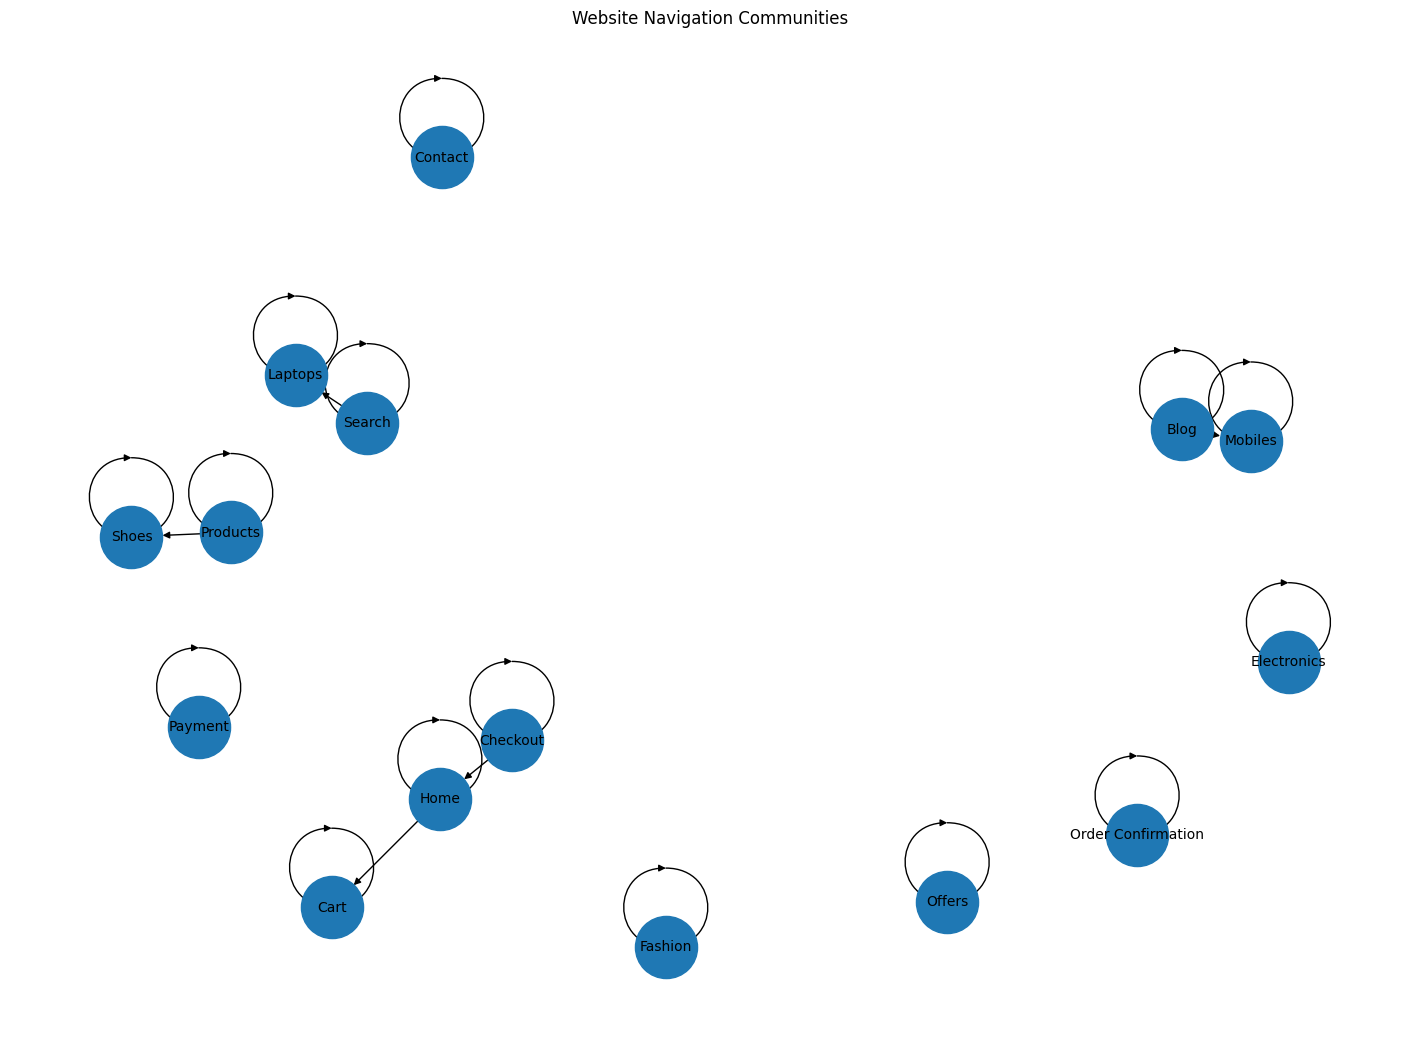

In [30]:
# CODE 38: Visualize webpage communities

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42)

# Draw graph
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2000,
    font_size=10,
    arrows=True
)

plt.title("Website Navigation Communities")
plt.show()

In [31]:
# CODE 39: Final graph analysis summary
# We display the main graph-analysis information
# completed so far.

print("GRAPH ANALYSIS SUMMARY")
print("======================")

print("Number of Webpages:", G.number_of_nodes())
print("Number of Navigation Links:", G.number_of_edges())

print("\nTop Pages by Degree Centrality:")
display(degree_df.head(5))

print("\nTop Pages by Closeness Centrality:")
display(closeness_df.head(5))

print("\nTop Pages by Betweenness Centrality:")
display(betweenness_df.head(5))

print("\nTop Pages by PageRank:")
display(pagerank_df.head(5))

print("\nNumber of Communities:", len(communities))

GRAPH ANALYSIS SUMMARY
Number of Webpages: 15
Number of Navigation Links: 20

Top Pages by Degree Centrality:


,Page,Degree Centrality
0,Home,0.285714
1,Mobiles,0.214286
2,Blog,0.214286
3,Cart,0.214286
4,Checkout,0.214286



Top Pages by Closeness Centrality:


,Page,Closeness Centrality
0,Cart,0.095238
1,Mobiles,0.071429
2,Home,0.071429
3,Shoes,0.071429
4,Laptops,0.071429



Top Pages by Betweenness Centrality:


,Page,Betweenness Centrality
0,Home,0.005495
1,Mobiles,0.000000
2,Blog,0.000000
3,Cart,0.000000
4,Checkout,0.000000



Top Pages by PageRank:


,Page,PageRank
0,Mobiles,0.099047
1,Laptops,0.096491
2,Cart,0.090938
3,Shoes,0.085870
4,Home,0.081476



Number of Communities: 13


In [32]:
# CODE 40: Save all graph analysis results
# These files can be used later for the dashboard
# or for further analysis.

degree_df.to_csv("degree_centrality.csv", index=False)

closeness_df.to_csv(
    "closeness_centrality.csv",
    index=False
)

betweenness_df.to_csv(
    "betweenness_centrality.csv",
    index=False
)

eigenvector_df.to_csv(
    "eigenvector_centrality.csv",
    index=False
)

pagerank_df.to_csv(
    "pagerank_results.csv",
    index=False
)

community_df.to_csv(
    "community_results.csv",
    index=False
)

transition_counts.to_csv(
    "navigation_transitions.csv",
    index=False
)

print("All graph analysis results saved successfully!")

All graph analysis results saved successfully!
